In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import librosa
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path.cwd()
AUDIO_DIR = ROOT / "audio"
CSV_PATH = ROOT / "esc50.csv"

assert AUDIO_DIR.is_dir(), f"Не найдена папка: {AUDIO_DIR}"
assert CSV_PATH.is_file(), f"Не найден файл: {CSV_PATH}"

print("Устройство:", DEVICE)

if DEVICE.type == "cuda":
    print("Видеокарта:", torch.cuda.get_device_name(0))
else:
    print("GPU недоступен для PyTorch — проверь окружение.")

print("Папка проекта:", ROOT)

Устройство: cuda
Видеокарта: NVIDIA GeForce RTX 5070 Ti
Папка проекта: /home/mlguest/notebooks/lesson 46


In [2]:
CLASSES = [
    "dog",
    "rain",
    "sea_waves",
    "crying_baby",
    "clock_tick",
    "sneezing",
    "helicopter",
    "chainsaw",
    "rooster",
    "crackling_fire",
]

NUM_CLASSES = len(CLASSES)
class_to_idx = {name: idx for idx, name in enumerate(CLASSES)}

df = pd.read_csv(CSV_PATH)

missing_classes = set(CLASSES) - set(df["category"])
assert not missing_classes, f"Нет таких классов: {missing_classes}"

df = df[df["category"].isin(CLASSES)].copy()
df["label"] = df["category"].map(class_to_idx)
df["path"] = df["filename"].map(lambda name: AUDIO_DIR / name)

missing_files = [str(path) for path in df["path"] if not path.is_file()]
assert not missing_files, f"Не найдены аудиофайлы: {missing_files[:5]}"

train_df = df[df["fold"].isin([1, 2, 3])].reset_index(drop=True)
val_df = df[df["fold"] == 4].reset_index(drop=True)
test_df = df[df["fold"] == 5].reset_index(drop=True)

print(f"Всего исходных записей: {len(df)}")
print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")

display(
    pd.crosstab(df["category"], df["fold"])
    .reindex(CLASSES)
)

Всего исходных записей: 400
Train: 240
Validation: 80
Test: 80


fold,1,2,3,4,5
category,,,,,
dog,8,8,8,8,8
rain,8,8,8,8,8
sea_waves,8,8,8,8,8
crying_baby,8,8,8,8,8
clock_tick,8,8,8,8,8
sneezing,8,8,8,8,8
helicopter,8,8,8,8,8
chainsaw,8,8,8,8,8
rooster,8,8,8,8,8


In [3]:
from itertools import combinations
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from IPython.display import Audio, display

SR = 22050
DURATION = 5
N_SAMPLES = SR * DURATION

N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64

def load_audio_part(frame):
    waves = []
    labels = []

    for row in tqdm(
        frame.itertuples(index=False),
        total=len(frame),
        desc="Загрузка аудио"
    ):
        wave, _ = librosa.load(
            str(row.path),
            sr=SR,
            mono=True
        )

        wave = librosa.util.fix_length(wave, size=N_SAMPLES)
        wave = wave.astype(np.float32)
        wave = wave - wave.mean()

        rms = np.sqrt(np.mean(wave ** 2))

        if rms < 1e-8:
            raise ValueError(f"Пустая или слишком тихая запись: {row.path}")

        wave = wave / rms

        waves.append(wave)
        labels.append(row.label)

    return (
        torch.from_numpy(np.stack(waves)),
        np.asarray(labels, dtype=np.int64)
    )

train_waves, train_labels = load_audio_part(train_df)
val_waves, val_labels = load_audio_part(val_df)
test_waves, test_labels = load_audio_part(test_df)

print("Train:", train_waves.shape)
print("Validation:", val_waves.shape)
print("Test:", test_waves.shape)

/home/mlguest/miniforge3/envs/torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Загрузка аудио: 100%|██████████| 80/80 [00:00<00:00, 608.98it/s]

Train: torch.Size([240, 110250])
Validation: torch.Size([80, 110250])
Test: torch.Size([80, 110250])


In [4]:
class SoundMixtureDataset(Dataset):
    def __init__(
        self,
        waves,
        labels,
        training=False,
        epoch_size=3600,
        seed=42
    ):
        self.waves = waves
        self.labels = np.asarray(labels)
        self.training = training
        self.epoch_size = epoch_size
        self.rng = np.random.default_rng(seed)

        self.class_ids = np.unique(self.labels)

        self.indices_by_class = {
            int(c): np.flatnonzero(self.labels == c)
            for c in self.class_ids
        }

        self.fixed_pairs = []

        if not training:
            for c1, c2 in combinations(self.class_ids, 2):
                for i in self.indices_by_class[int(c1)]:
                    for j in self.indices_by_class[int(c2)]:
                        relative_db = float(self.rng.uniform(-6, 6))
                        self.fixed_pairs.append(
                            (int(i), int(j), relative_db)
                        )

    def __len__(self):
        if self.training:
            return self.epoch_size
        return len(self.fixed_pairs)

    def __getitem__(self, index):
        if self.training:
            c1, c2 = self.rng.choice(
                self.class_ids,
                size=2,
                replace=False
            )

            i = int(self.rng.choice(self.indices_by_class[int(c1)]))
            j = int(self.rng.choice(self.indices_by_class[int(c2)]))
            relative_db = float(self.rng.uniform(-6, 6))
        else:
            i, j, relative_db = self.fixed_pairs[index]

        wave1 = self.waves[i]
        wave2 = self.waves[j]

        gain = 10.0 ** (relative_db / 20.0)
        mixture = wave1 + gain * wave2

        peak = mixture.abs().max().clamp_min(1e-8)
        mixture = 0.95 * mixture / peak

        target = torch.zeros(NUM_CLASSES, dtype=torch.float32)
        target[int(self.labels[i])] = 1.0
        target[int(self.labels[j])] = 1.0

        return mixture, target


train_dataset = SoundMixtureDataset(
    train_waves,
    train_labels,
    training=True,
    epoch_size=3600,
    seed=SEED
)

val_dataset = SoundMixtureDataset(
    val_waves,
    val_labels,
    training=False,
    seed=SEED + 1
)

test_dataset = SoundMixtureDataset(
    test_waves,
    test_labels,
    training=False,
    seed=SEED + 2
)

BATCH_SIZE = 32

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,
    "pin_memory": DEVICE.type == "cuda"
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    **loader_options
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_options
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_options
)

print("Обучающих смесей за эпоху:", len(train_dataset))
print("Смесей validation:", len(val_dataset))
print("Смесей test:", len(test_dataset))

Обучающих смесей за эпоху: 3600
Смесей validation: 2880
Смесей test: 2880


In [5]:
example_wave, example_target = val_dataset[0]

example_classes = [
    CLASSES[i]
    for i in torch.where(example_target == 1)[0].tolist()
]

print("В смеси:", " + ".join(example_classes))
display(Audio(example_wave.numpy(), rate=SR))

В смеси: dog + rain


In [6]:
class LogMelFrontend(nn.Module):
    def __init__(self):
        super().__init__()

        mel_filters = librosa.filters.mel(
            sr=SR,
            n_fft=N_FFT,
            n_mels=N_MELS,
            fmin=20,
            fmax=SR / 2
        )

        self.register_buffer(
            "mel_filters",
            torch.tensor(mel_filters, dtype=torch.float32)
        )

        self.register_buffer(
            "window",
            torch.hann_window(N_FFT)
        )

    def forward(self, waves):
        spectrum = torch.stft(
            waves,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            win_length=N_FFT,
            window=self.window,
            center=True,
            return_complex=True
        )

        power = spectrum.abs().square()
        mel_power = torch.matmul(self.mel_filters, power)

        log_mel = 10.0 * torch.log10(mel_power.clamp_min(1e-10))

        peak_db = log_mel.amax(dim=(1, 2), keepdim=True)
        log_mel = torch.maximum(log_mel, peak_db - 80.0)

        mean = log_mel.mean(dim=(1, 2), keepdim=True)
        std = log_mel.std(
            dim=(1, 2),
            keepdim=True,
            unbiased=False
        ).clamp_min(1e-5)

        log_mel = (log_mel - mean) / std

        return log_mel.unsqueeze(1)

In [7]:
class SoundCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.frontend = LogMelFrontend()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, waves):
        x = self.frontend(waves)
        x = self.features(x)
        return self.classifier(x)


model = SoundCNN(NUM_CLASSES).to(DEVICE)

parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Обучаемых параметров:", f"{parameter_count:,}")
print("Устройство модели:", next(model.parameters()).device)

with torch.no_grad():
    sample_output = model(
        example_wave.unsqueeze(0).to(DEVICE)
    )

print("Форма выхода:", sample_output.shape)

Обучаемых параметров: 101,802
Устройство модели: cuda:0
Форма выхода: torch.Size([1, 10])


In [8]:
def top2_predictions(logits):
    indices = logits.topk(k=2, dim=1).indices

    predictions = torch.zeros_like(logits)
    predictions.scatter_(1, indices, 1.0)

    return predictions


def calculate_metrics(targets, predictions):
    return {
        "exact_match": accuracy_score(targets, predictions),
        "micro_f1": f1_score(
            targets, predictions,
            average="micro", zero_division=0
        ),
        "macro_f1": f1_score(
            targets, predictions,
            average="macro", zero_division=0
        )
    }


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    loss_sum = 0.0
    sample_count = 0

    for waves, targets in loader:
        waves = waves.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(waves)
        loss = criterion(logits, targets)

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        batch_size = waves.size(0)
        loss_sum += loss.item() * batch_size
        sample_count += batch_size

    return loss_sum / sample_count


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    loss_sum = 0.0
    sample_count = 0
    targets_all = []
    predictions_all = []
    scores_all = []

    for waves, targets in loader:
        waves = waves.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        logits = model(waves)
        loss = criterion(logits, targets)

        predictions = top2_predictions(logits)

        batch_size = waves.size(0)
        loss_sum += loss.item() * batch_size
        sample_count += batch_size

        targets_all.append(targets.cpu().numpy())
        predictions_all.append(predictions.cpu().numpy())
        scores_all.append(torch.sigmoid(logits).cpu().numpy())

    targets_all = np.concatenate(targets_all).astype(np.int64)
    predictions_all = np.concatenate(predictions_all).astype(np.int64)
    scores_all = np.concatenate(scores_all)

    metrics = calculate_metrics(targets_all, predictions_all)
    metrics["loss"] = loss_sum / sample_count

    return metrics, targets_all, predictions_all, scores_all

In [10]:
EPOCHS = 25
PATIENCE = 12

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4
)

history = []
best_score = -float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_metrics, _, _, _ = evaluate(
        model,
        val_loader,
        criterion
    )

    score = val_metrics["macro_f1"]
    scheduler.step(score)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_micro_f1": val_metrics["micro_f1"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_exact_match": val_metrics["exact_match"]
    })

    print(
        f"Эпоха {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Macro F1: {score:.4f} | "
        f"Точная пара: {val_metrics['exact_match']:.4f}"
    )

    if score > best_score + 1e-4:
        best_score = score
        best_epoch = epoch

        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nРанняя остановка.")
        break

model.load_state_dict(best_state)
model.eval()

print(f"\nВосстановлена модель с эпохи {best_epoch}")
print(f"Лучший Macro F1 на validation: {best_score:.4f}")

Эпоха 01/25 | Train loss: 0.2698 | Val loss: 0.2760 | Macro F1: 0.6672 | Точная пара: 0.3854
Эпоха 02/25 | Train loss: 0.2565 | Val loss: 0.3406 | Macro F1: 0.5935 | Точная пара: 0.3097
Эпоха 03/25 | Train loss: 0.2479 | Val loss: 0.2670 | Macro F1: 0.7033 | Точная пара: 0.4135
Эпоха 04/25 | Train loss: 0.2363 | Val loss: 0.2985 | Macro F1: 0.6590 | Точная пара: 0.3510
Эпоха 05/25 | Train loss: 0.2282 | Val loss: 0.2925 | Macro F1: 0.6759 | Точная пара: 0.3694
Эпоха 06/25 | Train loss: 0.2227 | Val loss: 0.2718 | Macro F1: 0.6802 | Точная пара: 0.3833
Эпоха 07/25 | Train loss: 0.2143 | Val loss: 0.2646 | Macro F1: 0.6886 | Точная пара: 0.4358
Эпоха 08/25 | Train loss: 0.2123 | Val loss: 0.2855 | Macro F1: 0.6732 | Точная пара: 0.3962
Эпоха 09/25 | Train loss: 0.1977 | Val loss: 0.2729 | Macro F1: 0.6880 | Точная пара: 0.4323
Эпоха 10/25 | Train loss: 0.1939 | Val loss: 0.2259 | Macro F1: 0.7529 | Точная пара: 0.5253
Эпоха 11/25 | Train loss: 0.1945 | Val loss: 0.2546 | Macro F1: 0.7251

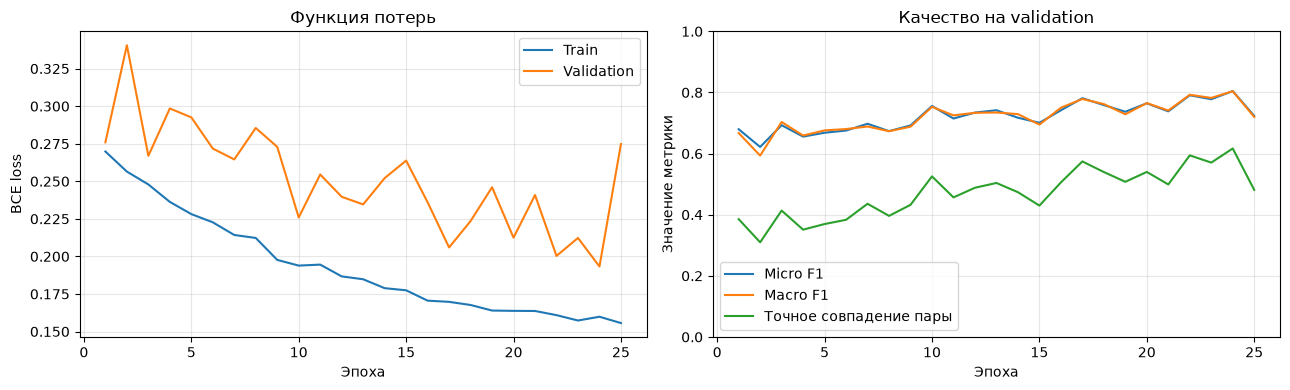

In [11]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("BCE loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["val_micro_f1"],
    label="Micro F1"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Macro F1"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_exact_match"],
    label="Точное совпадение пары"
)
axes[1].set_title("Качество на validation")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Значение метрики")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
test_metrics, y_true, y_pred, y_scores = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Точное совпадение: {test_metrics['exact_match']:.4f}")
print(f"Micro F1: {test_metrics['micro_f1']:.4f}")
print(f"Macro F1: {test_metrics['macro_f1']:.4f}")

print("\nОтчёт по классам:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

Точное совпадение: 0.4892
Micro F1: 0.7361
Macro F1: 0.7303

Отчёт по классам:

                precision    recall  f1-score   support

           dog     0.5676    0.6198    0.5925       576
          rain     0.7763    0.9340    0.8479       576
     sea_waves     0.8924    0.7917    0.8390       576
   crying_baby     0.8344    0.9010    0.8664       576
    clock_tick     0.8353    0.6250    0.7150       576
      sneezing     0.5324    0.3420    0.4165       576
    helicopter     0.5738    0.6007    0.5869       576
      chainsaw     0.9364    0.8438    0.8877       576
       rooster     0.6544    0.8976    0.7570       576
crackling_fire     0.7838    0.8056    0.7945       576

     micro avg     0.7361    0.7361    0.7361      5760
     macro avg     0.7387    0.7361    0.7303      5760
  weighted avg     0.7387    0.7361    0.7303      5760
   samples avg     0.7361    0.7361    0.7361      5760



CNN+BiGRU

In [13]:
class SoundCRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.frontend = LogMelFrontend()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),

            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),

            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d((2, 2))
        )

        self.gru = nn.GRU(
            input_size=128,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, waves):
        x = self.frontend(waves)
        x = self.features(x)

        # [batch, channels, frequency, time] → [batch, time, channels]
        x = x.mean(dim=2)
        x = x.transpose(1, 2).contiguous()

        x, _ = self.gru(x)

        mean_features = x.mean(dim=1)
        max_features = x.amax(dim=1)

        x = torch.cat([mean_features, max_features], dim=1)

        return self.classifier(x)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

crnn = SoundCRNN(NUM_CLASSES).to(DEVICE)

print("Устройство:", next(crnn.parameters()).device)
print(
    "Обучаемых параметров:",
    f"{sum(p.numel() for p in crnn.parameters() if p.requires_grad):,}"
)

Устройство: cuda:0
Обучаемых параметров: 184,490


In [14]:
crnn_train_dataset = SoundMixtureDataset(
    train_waves,
    train_labels,
    training=True,
    epoch_size=3600,
    seed=SEED
)

crnn_generator = torch.Generator().manual_seed(SEED)

crnn_train_loader = DataLoader(
    crnn_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
    generator=crnn_generator
)

crnn_val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)

crnn_test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)

In [15]:
import time

CRNN_EPOCHS = 25
CRNN_PATIENCE = 12
CRNN_PATH = ROOT / "sound_crnn_best.pth"

crnn_criterion = nn.BCEWithLogitsLoss()

crnn_optimizer = torch.optim.AdamW(
    crnn.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

crnn_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    crnn_optimizer,
    mode="max",
    factor=0.5,
    patience=4
)

crnn_history = []
crnn_best_score = -float("inf")
crnn_best_epoch = 0
crnn_best_state = None
crnn_wait = 0

try:
    for epoch in range(1, CRNN_EPOCHS + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        started = time.perf_counter()
        current_lr = crnn_optimizer.param_groups[0]["lr"]

        train_loss = train_one_epoch(
            crnn,
            crnn_train_loader,
            crnn_optimizer,
            crnn_criterion
        )

        val_metrics, _, _, _ = evaluate(
            crnn,
            crnn_val_loader,
            crnn_criterion
        )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - started
        score = val_metrics["macro_f1"]

        crnn_scheduler.step(score)

        crnn_history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_micro_f1": val_metrics["micro_f1"],
            "val_macro_f1": score,
            "val_exact_match": val_metrics["exact_match"],
            "lr": current_lr,
            "seconds": elapsed
        })

        if score > crnn_best_score + 1e-4:
            crnn_best_score = score
            crnn_best_epoch = epoch
            crnn_wait = 0

            crnn_best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in crnn.state_dict().items()
            }

            torch.save(
                {
                    "model_state_dict": crnn_best_state,
                    "classes": CLASSES,
                    "best_epoch": crnn_best_epoch,
                    "best_macro_f1": crnn_best_score,
                    "sr": SR,
                    "duration": DURATION,
                    "n_fft": N_FFT,
                    "hop_length": HOP_LENGTH,
                    "n_mels": N_MELS
                },
                CRNN_PATH
            )
        else:
            crnn_wait += 1

        pd.DataFrame(crnn_history).to_csv(
            ROOT / "crnn_training_history.csv",
            index=False
        )

        print(
            f"Эпоха {epoch:02d}/{CRNN_EPOCHS} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_metrics['loss']:.4f} | "
            f"Macro F1: {score:.4f} | "
            f"Точная пара: {val_metrics['exact_match']:.4f} | "
            f"LR: {current_lr:.6f} | "
            f"{elapsed:.1f} с",
            flush=True
        )

        if crnn_wait >= CRNN_PATIENCE:
            print("\nРанняя остановка.")
            break

except KeyboardInterrupt:
    print("\nОбучение остановлено пользователем.")

finally:
    if crnn_best_state is not None:
        crnn.load_state_dict(crnn_best_state)
        crnn.eval()

        print(f"\nВосстановлена эпоха {crnn_best_epoch}")
        print(f"Лучший validation Macro F1: {crnn_best_score:.4f}")
    else:
        print("Пока нет результатов завершённой эпохи.")

Эпоха 01/25 | Train: 0.4574 | Val: 0.3769 | Macro F1: 0.5471 | Точная пара: 0.1976 | LR: 0.001000 | 21.1 с
Эпоха 02/25 | Train: 0.3239 | Val: 0.2662 | Macro F1: 0.6988 | Точная пара: 0.4240 | LR: 0.001000 | 15.3 с
Эпоха 03/25 | Train: 0.2442 | Val: 0.2295 | Macro F1: 0.7808 | Точная пара: 0.5795 | LR: 0.001000 | 7.3 с
Эпоха 04/25 | Train: 0.1907 | Val: 0.2326 | Macro F1: 0.7754 | Точная пара: 0.5764 | LR: 0.001000 | 6.6 с
Эпоха 05/25 | Train: 0.1501 | Val: 0.2774 | Macro F1: 0.7000 | Точная пара: 0.4576 | LR: 0.001000 | 7.0 с
Эпоха 06/25 | Train: 0.1255 | Val: 0.1840 | Macro F1: 0.8372 | Точная пара: 0.6903 | LR: 0.001000 | 6.4 с
Эпоха 07/25 | Train: 0.1051 | Val: 0.1879 | Macro F1: 0.8271 | Точная пара: 0.6715 | LR: 0.001000 | 7.1 с
Эпоха 08/25 | Train: 0.0985 | Val: 0.1476 | Macro F1: 0.8660 | Точная пара: 0.7493 | LR: 0.001000 | 7.9 с
Эпоха 09/25 | Train: 0.0851 | Val: 0.2161 | Macro F1: 0.8174 | Точная пара: 0.6521 | LR: 0.001000 | 8.0 с
Эпоха 10/25 | Train: 0.0793 | Val: 0.1840 | 

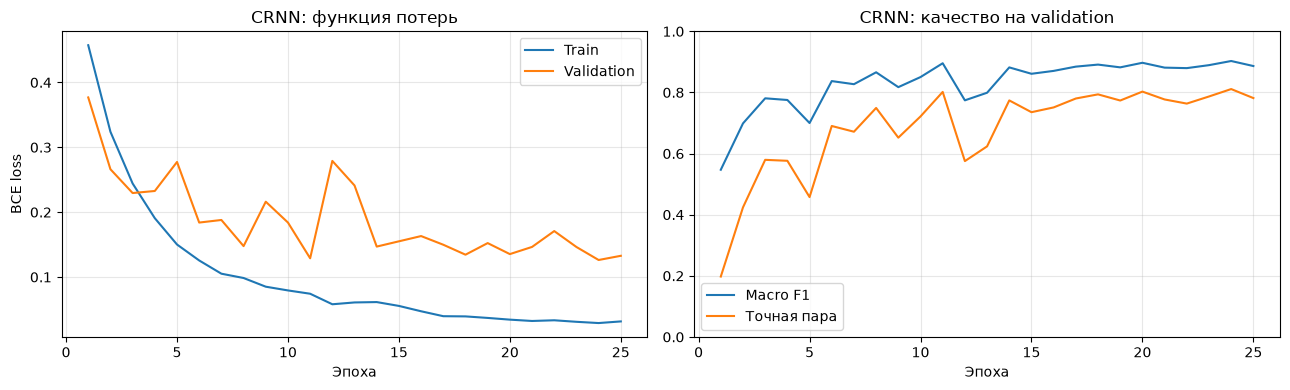

In [16]:
crnn_history_df = pd.DataFrame(crnn_history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    crnn_history_df["epoch"],
    crnn_history_df["train_loss"],
    label="Train"
)
axes[0].plot(
    crnn_history_df["epoch"],
    crnn_history_df["val_loss"],
    label="Validation"
)
axes[0].set_title("CRNN: функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("BCE loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    crnn_history_df["epoch"],
    crnn_history_df["val_macro_f1"],
    label="Macro F1"
)
axes[1].plot(
    crnn_history_df["epoch"],
    crnn_history_df["val_exact_match"],
    label="Точная пара"
)
axes[1].set_title("CRNN: качество на validation")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
assert crnn_best_state is not None, "Сначала заверши хотя бы одну эпоху."

crnn_test_metrics, crnn_y_true, crnn_y_pred, crnn_y_scores = evaluate(
    crnn,
    crnn_test_loader,
    crnn_criterion
)

print(f"Точное совпадение: {crnn_test_metrics['exact_match']:.4f}")
print(f"Micro F1: {crnn_test_metrics['micro_f1']:.4f}")
print(f"Macro F1: {crnn_test_metrics['macro_f1']:.4f}")

print("\nОтчёт по классам:\n")

print(
    classification_report(
        crnn_y_true,
        crnn_y_pred,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

comparison = pd.DataFrame([
    {
        "Модель": "CNN",
        "Точная пара": 0.4830,
        "Micro F1": 0.7293,
        "Macro F1": 0.7225
    },
    {
        "Модель": "CRNN",
        "Точная пара": crnn_test_metrics["exact_match"],
        "Micro F1": crnn_test_metrics["micro_f1"],
        "Macro F1": crnn_test_metrics["macro_f1"]
    }
]).set_index("Модель")

display(comparison.round(4))

Точное совпадение: 0.6951
Micro F1: 0.8438
Macro F1: 0.8454

Отчёт по классам:

                precision    recall  f1-score   support

           dog     0.6814    0.9653    0.7989       576
          rain     0.7244    0.9948    0.8383       576
     sea_waves     0.9903    0.8872    0.9359       576
   crying_baby     1.0000    0.8333    0.9091       576
    clock_tick     0.8880    0.7708    0.8253       576
      sneezing     0.9932    0.7639    0.8636       576
    helicopter     0.6630    0.7344    0.6969       576
      chainsaw     0.9737    0.8368    0.9001       576
       rooster     0.8382    0.9983    0.9113       576
crackling_fire     0.9519    0.6528    0.7745       576

     micro avg     0.8438    0.8438    0.8438      5760
     macro avg     0.8704    0.8438    0.8454      5760
  weighted avg     0.8704    0.8438    0.8454      5760
   samples avg     0.8438    0.8438    0.8438      5760



,Точная пара,Micro F1,Macro F1
Модель,,,
CNN,0.4830,0.7293,0.7225
CRNN,0.6951,0.8438,0.8454


In [18]:
from IPython.display import Audio, display

REAL_DIR = ROOT / "real_audio"

real_records = [
    {
        "filename": "rain_dog.wav",
        "expected": ["rain", "dog"],
        "start": 0.0
    },
    {
        "filename": "rain_waves.wav",
        "expected": ["rain", "sea_waves"],
        "start": 0.0
    },
    {
        "filename": "dog_rain.mp3",
        "expected": ["dog", "rain"],
        "start": 0.0
    }
]

real_audio = {}

for record in real_records:
    path = REAL_DIR / record["filename"]

    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

    wave, _ = librosa.load(str(path), sr=SR, mono=True)
    real_audio[record["filename"]] = wave

    print(
        record["filename"],
        f"— длительность {len(wave) / SR:.1f} с"
    )
    display(Audio(wave, rate=SR))

rain_dog.wav — длительность 44.2 с


rain_waves.wav — длительность 39.2 с


dog_rain.mp3 — длительность 22.1 с


In [19]:
real_records[0]["start"] = 0.0
real_records[1]["start"] = 0.0
real_records[2]["start"] = 10.0


def get_real_segment(record):
    wave = real_audio[record["filename"]]

    start = int(round(record["start"] * SR))
    end = start + N_SAMPLES

    if start < 0 or end > len(wave):
        raise ValueError(
            f"{record['filename']}: выбери начало так, "
            "чтобы оставалось минимум 5 секунд."
        )

    segment = wave[start:end].copy()
    segment = segment - segment.mean()

    peak = np.max(np.abs(segment))

    if peak < 1e-8:
        raise ValueError("Выбранный фрагмент содержит тишину.")

    segment = 0.95 * segment / peak

    return torch.from_numpy(segment.astype(np.float32))


for record in real_records:
    segment = get_real_segment(record)

    print(
        f"{record['filename']}: "
        f"{record['start']:.1f}–{record['start'] + DURATION:.1f} с"
    )
    print("Проверяем на слух:", " + ".join(record["expected"]))

    display(Audio(segment.numpy(), rate=SR))

rain_dog.wav: 0.0–5.0 с
Проверяем на слух: rain + dog


rain_waves.wav: 0.0–5.0 с
Проверяем на слух: rain + sea_waves


dog_rain.mp3: 10.0–15.0 с
Проверяем на слух: dog + rain


In [20]:
models_to_check = {}

if "best_state" in globals() and best_state is not None:
    model.load_state_dict(best_state)

models_to_check["CNN"] = model

if (
    "crnn" in globals()
    and "crnn_best_state" in globals()
    and crnn_best_state is not None
):
    crnn.load_state_dict(crnn_best_state)
    models_to_check["CRNN"] = crnn


@torch.no_grad()
def predict_real_segment(net, segment):
    net.eval()

    device = next(net.parameters()).device
    logits = net(segment.unsqueeze(0).to(device))
    scores = torch.sigmoid(logits)[0].cpu().numpy()

    top_indices = np.argsort(scores)[::-1][:2]

    return scores, [CLASSES[i] for i in top_indices]


results = []

for record in real_records:
    segment = get_real_segment(record)

    for model_name, net in models_to_check.items():
        scores, predicted = predict_real_segment(net, segment)

        results.append({
            "Файл": record["filename"],
            "Начало, с": record["start"],
            "Модель": model_name,
            "Ожидается": " + ".join(record["expected"]),
            "Предсказано": " + ".join(predicted),
            "Совпала пара": set(predicted) == set(record["expected"])
        })

        print(f"\n{record['filename']} — {model_name}")

        display(
            pd.DataFrame({
                "Класс": CLASSES,
                "Sigmoid": scores
            })
            .sort_values("Sigmoid", ascending=False)
            .reset_index(drop=True)
            .round(4)
        )

results_df = pd.DataFrame(results)
display(results_df)


rain_dog.wav — CNN


,Класс,Sigmoid
0,rain,0.9992
1,dog,0.5705
2,sneezing,0.2776
3,crackling_fire,0.0192
4,helicopter,0.0052
5,sea_waves,0.0051
6,rooster,0.0028
7,clock_tick,0.0004
8,chainsaw,0.0003
9,crying_baby,0.0002



rain_dog.wav — CRNN


,Класс,Sigmoid
0,rain,1.0000
1,dog,0.9958
2,sneezing,0.0008
3,clock_tick,0.0000
4,helicopter,0.0000
5,crying_baby,0.0000
6,rooster,0.0000
7,chainsaw,0.0000
8,crackling_fire,0.0000
9,sea_waves,0.0000



rain_waves.wav — CNN


,Класс,Sigmoid
0,sea_waves,0.8198
1,helicopter,0.5693
2,sneezing,0.2959
3,dog,0.1398
4,crackling_fire,0.1150
5,rooster,0.0190
6,rain,0.0072
7,clock_tick,0.0071
8,crying_baby,0.0026
9,chainsaw,0.0007


... (3 outputs left out)

,Класс,Sigmoid
0,rain,0.8583
1,dog,0.6014
2,sneezing,0.2555
3,sea_waves,0.2178
4,crackling_fire,0.0974
5,rooster,0.0842
6,crying_baby,0.0024
7,clock_tick,0.0011
8,helicopter,0.0006
9,chainsaw,0.0004



dog_rain.mp3 — CRNN


,Класс,Sigmoid
0,rain,0.9996
1,dog,0.9993
2,crackling_fire,0.0206
3,rooster,0.0002
4,sneezing,0.0001
5,clock_tick,0.0000
6,sea_waves,0.0000
7,chainsaw,0.0000
8,crying_baby,0.0000
9,helicopter,0.0000


,Файл,"Начало, с",Модель,Ожидается,Предсказано,Совпала пара
0,rain_dog.wav,0.0,CNN,rain + dog,rain + dog,True
1,rain_dog.wav,0.0,CRNN,rain + dog,rain + dog,True
2,rain_waves.wav,0.0,CNN,rain + sea_waves,sea_waves + helicopter,False
3,rain_waves.wav,0.0,CRNN,rain + sea_waves,helicopter + crackling_fire,False
4,dog_rain.mp3,10.0,CNN,dog + rain,rain + dog,True
5,dog_rain.mp3,10.0,CRNN,dog + rain,rain + dog,True


In [21]:
from pathlib import Path

import librosa
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from transformers import (
    ASTFeatureExtractor,
    ASTForAudioClassification,
    ClapModel,
    ClapProcessor,
)

hf_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", hf_device)

audio_dir = Path.cwd() / "real_audio"

samples = [
    ("rain_dog.wav",   0.0, {"rain", "dog"}),
    ("rain_waves.wav", 0.0, {"rain", "sea_waves"}),
    ("dog_rain.mp3",  10.0, {"dog", "rain"}),
]

hf_classes = [
    "dog", "rain", "sea_waves", "crying_baby", "clock_tick",
    "sneezing", "helicopter", "chainsaw", "rooster", "crackling_fire",
]


def load_segments(sample_rate):
    segments = []
    for filename, start, _ in samples:
        path = audio_dir / filename
        if not path.is_file():
            raise FileNotFoundError(f"Не найден файл: {path}")

        wave, _ = librosa.load(
            path, sr=sample_rate, mono=True, offset=start, duration=5.0
        )
        if len(wave) != 5 * sample_rate:
            raise ValueError(f"{filename}: с {start} с нет полных пяти секунд.")

        wave = wave - wave.mean()
        peak = np.max(np.abs(wave))
        if peak < 1e-8:
            raise ValueError(f"{filename}: выбранный отрезок содержит тишину.")

        segments.append((0.95 * wave / peak).astype(np.float32))
    return segments


def make_results(model_name, class_scores):
    rows = []
    for (filename, start, expected), scores in zip(samples, class_scores):
        indices = np.argsort(-scores)[:2]
        predicted = [hf_classes[i] for i in indices]

        rows.append({
            "Файл": filename,
            "Начало, с": start,
            "Модель": model_name,
            "Ожидается": " + ".join(sorted(expected)),
            "Предсказано": " + ".join(predicted),
            "Совпало звуков": len(expected.intersection(predicted)),
            "Совпала пара": set(predicted) == expected,
        })
    return pd.DataFrame(rows)

Устройство: cuda


In [22]:
ast_id = "MIT/ast-finetuned-audioset-10-10-0.4593"

ast_extractor = ASTFeatureExtractor.from_pretrained(ast_id)
ast_model = ASTForAudioClassification.from_pretrained(ast_id).to(hf_device).eval()

ast_labels = {
    "dog": ["Dog", "Bark"],
    "rain": ["Rain"],
    "sea_waves": ["Waves, surf"],
    "crying_baby": ["Baby cry, infant cry"],
    "clock_tick": ["Tick-tock"],
    "sneezing": ["Sneeze"],
    "helicopter": ["Helicopter"],
    "chainsaw": ["Chainsaw"],
    "rooster": ["Crowing, cock-a-doodle-doo"],
    "crackling_fire": ["Fire", "Crackle"],
}

sr_ast = ast_extractor.sampling_rate
ast_inputs = ast_extractor(
    load_segments(sr_ast),
    sampling_rate=sr_ast,
    return_tensors="pt",
).to(hf_device)

with torch.inference_mode():
    ast_scores = ast_model(**ast_inputs).logits.sigmoid().cpu().numpy()

label_ids = ast_model.config.label2id
ast_scores_10 = np.column_stack([
    ast_scores[:, [label_ids[label] for label in ast_labels[name]]].max(axis=1)
    for name in hf_classes
])

ast_results = make_results("AST", ast_scores_10)
display(ast_results)

# Освобождаем видеопамять перед загрузкой CLAP
del ast_model, ast_inputs
if hf_device.type == "cuda":
    torch.cuda.empty_cache()

,Файл,"Начало, с",Модель,Ожидается,Предсказано,Совпало звуков,Совпала пара
0,rain_dog.wav,0.0,AST,dog + rain,rain + dog,2,True
1,rain_waves.wav,0.0,AST,rain + sea_waves,rain + crackling_fire,1,False
2,dog_rain.mp3,10.0,AST,dog + rain,rain + dog,2,True


In [24]:
def load_segments(sample_rate):
    target_length = 5 * sample_rate
    segments = []

    for filename, start, _ in samples:
        wave, original_sr = librosa.load(
            audio_dir / filename, sr=None, mono=True
        )

        first = round(start * original_sr)
        clip = wave[first:first + 5 * original_sr]
        duration = len(clip) / original_sr

        print(f"{filename}: с {start:.1f} с доступно {duration:.4f} с из 5")

        # Допускаем расхождение до 1 мс из-за округления длины.
        if duration < 4.999:
            raise ValueError(
                f"{filename}: длительность всего файла {len(wave) / original_sr:.3f} с. "
                f"С отметки {start:.1f} с доступно только {duration:.3f} с."
            )

        clip = librosa.resample(
            clip, orig_sr=original_sr, target_sr=sample_rate
        )
        clip = librosa.util.fix_length(clip, size=target_length)

        clip = clip - clip.mean()
        peak = np.max(np.abs(clip))
        if peak < 1e-8:
            raise ValueError(f"{filename}: выбранный фрагмент содержит тишину.")

        segments.append((0.95 * clip / peak).astype(np.float32))

    return segments

In [25]:
clap_id = "laion/clap-htsat-unfused"

clap_processor = ClapProcessor.from_pretrained(clap_id)
clap_model = ClapModel.from_pretrained(clap_id).to(hf_device).eval()

descriptions = {
    "dog": "A dog barking.",
    "rain": "The sound of falling rain.",
    "sea_waves": "Ocean waves breaking on the shore.",
    "crying_baby": "A baby crying.",
    "clock_tick": "The rhythmic ticking of a clock.",
    "sneezing": "A person sneezing.",
    "helicopter": "The rotor blades of a helicopter flying overhead.",
    "chainsaw": "A running chainsaw cutting wood.",
    "rooster": "A rooster crowing.",
    "crackling_fire": "A wood fire crackling and popping.",
}

sr_clap = clap_processor.feature_extractor.sampling_rate

clap_inputs = clap_processor(
    text=[descriptions[name] for name in hf_classes],
    audios=load_segments(sr_clap),
    sampling_rate=sr_clap,
    padding=True,
    return_tensors="pt",
).to(hf_device)

with torch.inference_mode():
    clap_scores = clap_model(**clap_inputs).logits_per_audio.cpu().numpy()

clap_results = make_results("CLAP", clap_scores)
display(clap_results)

del clap_model, clap_inputs
if hf_device.type == "cuda":
    torch.cuda.empty_cache()

rain_dog.wav: с 0.0 с доступно 5.0000 с из 5
rain_waves.wav: с 0.0 с доступно 5.0000 с из 5
dog_rain.mp3: с 10.0 с доступно 5.0000 с из 5


,Файл,"Начало, с",Модель,Ожидается,Предсказано,Совпало звуков,Совпала пара
0,rain_dog.wav,0.0,CLAP,dog + rain,rain + dog,2,True
1,rain_waves.wav,0.0,CLAP,rain + sea_waves,rain + sea_waves,2,True
2,dog_rain.mp3,10.0,CLAP,dog + rain,rain + dog,2,True


In [26]:
tables = [ast_results, clap_results]

if "results_df" in globals():
    previous = results_df[
        results_df["Модель"].isin(["CNN", "CRNN"])
    ].copy()

    previous["Совпало звуков"] = [
        len(set(expected.split(" + ")) & set(predicted.split(" + ")))
        for expected, predicted in zip(previous["Ожидается"], previous["Предсказано"])
    ]

    tables.insert(0, previous)

comparison_real = pd.concat(tables, ignore_index=True)

display(
    comparison_real[
        ["Файл", "Начало, с", "Модель", "Ожидается",
         "Предсказано", "Совпало звуков", "Совпала пара"]
    ].sort_values(["Файл", "Модель"]).reset_index(drop=True)
)

summary_real = comparison_real.groupby("Модель").agg(
    Проверено=("Файл", "count"),
    Верных_пар=("Совпала пара", "sum"),
    Угадано_звуков=("Совпало звуков", "sum"),
)
display(summary_real.sort_values(
    ["Верных_пар", "Угадано_звуков"], ascending=False
))

,Файл,"Начало, с",Модель,Ожидается,Предсказано,Совпало звуков,Совпала пара
0,dog_rain.mp3,10.0,AST,dog + rain,rain + dog,2,True
1,dog_rain.mp3,10.0,CLAP,dog + rain,rain + dog,2,True
2,dog_rain.mp3,10.0,CNN,dog + rain,rain + dog,2,True
3,dog_rain.mp3,10.0,CRNN,dog + rain,rain + dog,2,True
4,rain_dog.wav,0.0,AST,dog + rain,rain + dog,2,True
5,rain_dog.wav,0.0,CLAP,dog + rain,rain + dog,2,True
6,rain_dog.wav,0.0,CNN,rain + dog,rain + dog,2,True
7,rain_dog.wav,0.0,CRNN,rain + dog,rain + dog,2,True
8,rain_waves.wav,0.0,AST,rain + sea_waves,rain + crackling_fire,1,False
9,rain_waves.wav,0.0,CLAP,rain + sea_waves,rain + sea_waves,2,True


,Проверено,Верных_пар,Угадано_звуков
Модель,,,
CLAP,3,3,6
AST,3,2,5
CNN,3,2,5
CRNN,3,2,4


In [27]:
import numpy as np
import pandas as pd
import onnxruntime as ort
from huggingface_hub import hf_hub_download
from IPython.display import display

providers = ["CPUExecutionProvider"]
if "CUDAExecutionProvider" in ort.get_available_providers():
    providers.insert(0, "CUDAExecutionProvider")

# Индексы AudioSet берём из предыдущей ячейки AST.
# Например, dog объединяет выходы Dog и Bark.
target_indices = [
    [label_ids[label] for label in ast_labels[class_name]]
    for class_name in hf_classes
]


def recognize_onnx(model_name, repo_id, filename, sample_rate):
    model_path = hf_hub_download(repo_id=repo_id, filename=filename)
    session = ort.InferenceSession(model_path, providers=providers)

    audio_input = session.get_inputs()[0]
    print(f"{model_name} | {session.get_providers()[0]}")
    print(f"Вход модели: {audio_input.name}, форма: {audio_input.shape}")

    scores_for_files = []

    for wave in load_segments(sample_rate):
        # Для фиксированного входа учитываем длину из самого ONNX-файла.
        required_length = audio_input.shape[-1]
        if isinstance(required_length, int):
            if len(wave) > required_length:
                raise ValueError(
                    f"{model_name}: вход модели короче выбранных 5 секунд."
                )
            wave = np.pad(wave, (0, required_length - len(wave)))

        batch = np.ascontiguousarray(wave[None, :], dtype=np.float32)
        outputs = session.run(None, {audio_input.name: batch})

        # Ищем выход с оценками 527 классов AudioSet.
        score_outputs = [
            output for output in outputs
            if output.shape in [(527,), (1, 527)]
        ]
        if len(score_outputs) != 1:
            raise ValueError(
                f"{model_name}: неожиданные формы выходов "
                f"{[output.shape for output in outputs]}"
            )

        scores = score_outputs[0].reshape(527)
        scores_for_files.append([
            scores[indices].max() for indices in target_indices
        ])

    return make_results(model_name, np.asarray(scores_for_files))

In [28]:
ced_results = recognize_onnx(
    model_name="CED-Base",
    repo_id="mispeech/ced-base",
    filename="model.onnx",
    sample_rate=16000,
)

display(ced_results)

CED-Base | CPUExecutionProvider
Вход модели: waveform, форма: ['batch_size', 'audio_samples']
rain_dog.wav: с 0.0 с доступно 5.0000 с из 5
rain_waves.wav: с 0.0 с доступно 5.0000 с из 5
dog_rain.mp3: с 10.0 с доступно 5.0000 с из 5


,Файл,"Начало, с",Модель,Ожидается,Предсказано,Совпало звуков,Совпала пара
0,rain_dog.wav,0.0,CED-Base,dog + rain,rain + dog,2,True
1,rain_waves.wav,0.0,CED-Base,rain + sea_waves,rain + sea_waves,2,True
2,dog_rain.mp3,10.0,CED-Base,dog + rain,rain + dog,2,True


In [29]:
efficientat_results = recognize_onnx(
    model_name="EfficientAT",
    repo_id="minhducjp/webdonhac-models",
    filename="mn10_as.onnx",
    sample_rate=32000,
)

display(efficientat_results)

EfficientAT | CPUExecutionProvider
Вход модели: wave, форма: ['B', 160000]
rain_dog.wav: с 0.0 с доступно 5.0000 с из 5
rain_waves.wav: с 0.0 с доступно 5.0000 с из 5
dog_rain.mp3: с 10.0 с доступно 5.0000 с из 5


2026-11-08 22:55:23.694176884 [W:onnxruntime:, execution_frame.cc:905 VerifyOutputSizes] Expected shape from model of {-1,527} does not match actual shape of {527} for output probs
2026-11-08 22:55:23.703747443 [W:onnxruntime:, execution_frame.cc:905 VerifyOutputSizes] Expected shape from model of {-1,527} does not match actual shape of {527} for output probs
2026-11-08 22:55:23.709722684 [W:onnxruntime:, execution_frame.cc:905 VerifyOutputSizes] Expected shape from model of {-1,527} does not match actual shape of {527} for output probs


,Файл,"Начало, с",Модель,Ожидается,Предсказано,Совпало звуков,Совпала пара
0,rain_dog.wav,0.0,EfficientAT,dog + rain,dog + rain,2,True
1,rain_waves.wav,0.0,EfficientAT,rain + sea_waves,rain + crackling_fire,1,False
2,dog_rain.mp3,10.0,EfficientAT,dog + rain,dog + rain,2,True


In [30]:
all_results = pd.concat(
    [comparison_real, ced_results, efficientat_results],
    ignore_index=True
).drop_duplicates(
    subset=["Файл", "Начало, с", "Модель"],
    keep="last"
)

display(
    all_results.pivot(
        index=["Файл", "Начало, с"],
        columns="Модель",
        values="Предсказано"
    )
)

summary = (
    all_results.groupby("Модель")
    .agg(
        Проверено=("Файл", "count"),
        Верных_пар=("Совпала пара", "sum"),
        Угадано_звуков=("Совпало звуков", "sum"),
    )
    .sort_values(["Верных_пар", "Угадано_звуков"], ascending=False)
)

display(summary)

,Модель,AST,CED-Base,CLAP,CNN,CRNN,EfficientAT
Файл,"Начало, с",,,,,,
dog_rain.mp3,10.0,rain + dog,rain + dog,rain + dog,rain + dog,rain + dog,dog + rain
rain_dog.wav,0.0,rain + dog,rain + dog,rain + dog,rain + dog,rain + dog,dog + rain
rain_waves.wav,0.0,rain + crackling_fire,rain + sea_waves,rain + sea_waves,sea_waves + helicopter,helicopter + crackling_fire,rain + crackling_fire


,Проверено,Верных_пар,Угадано_звуков
Модель,,,
CED-Base,3,3,6
CLAP,3,3,6
AST,3,2,5
CNN,3,2,5
EfficientAT,3,2,5
CRNN,3,2,4
